# Exercise Sheet 5

In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Thursday October 3, 2025

@authors: Elena Raponi, Lennard Froma, Ivan Olarte-Rodriguez

Revised on Thursday October 8, 2026

@authors: Elena Raponi, Ivan Olarte-Rodriguez, Santiago García-Mayayo

"""
# Import the Libraries

# Typical Libraries for Numerical Processing
import numpy as np

from typing import Callable

# Import the PyTorch Libraries
import torch
from torch import Tensor
from torch.distributions import Normal

from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_mll
from botorch.models.transforms import Standardize
from botorch.models.transforms import Normalize

from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.likelihoods import FixedNoiseGaussianLikelihood
from gpytorch.kernels import MaternKernel, ScaleKernel, RBFKernel, Kernel
from gpytorch.means import ConstantMean, ZeroMean, Mean
from gpytorch.constraints import Interval, GreaterThan, Positive


# To handle partial
from functools import partial

# For sampling distributions with scipy
from scipy.stats import norm

# Import the os library to handle file paths and the math library for mathematical operations
import os.path
import math

from matplotlib import pyplot as plt

c:\ProgramData\anaconda3\envs\bo-course\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\ProgramData\anaconda3\envs\bo-course\Lib\site-packages\pyro\ops\stats.py:527: SyntaxWarning: invalid escape sequence '\g'
  we have :math:`ES^{*}(P,Q) \ge ES^{*}(Q,Q)` with equality holding if and only if :math:`P=Q`, i.e.


In the following block there are listed four different functions. Run this block in order to load the functions into the main module. These functions are then going to be switched to perform different approximations with the regressors.


In this section of the exercise you will now work with the acquisition functions. In the framework of Bayesian Optimization, you first need to build a surrogate model through a Gaussian Process Regression. With the information of the regressor, then you need to decide the next point of the decision space to pick. This decision process is evaluated through an acquisition function which points the "next most interesting point" according to some metric embedded into the acquistion function.

### Preliminaries:

[[0.12 0.18]
 [0.13 0.88]
 [0.15 0.25]
 [0.19 0.11]
 [0.55 0.62]
 [0.58 0.71]
 [0.63 0.59]
 [0.84 0.76]
 [0.88 0.83]
 [0.92 0.79]]


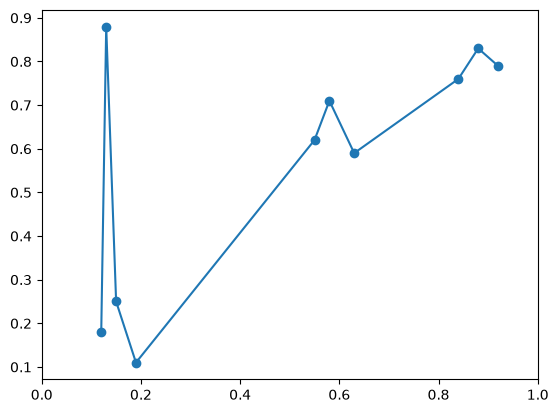

In [2]:


# Scikit Learn Libraries (For handling basic Regression Processes)
# Read in data from a file.  Download this from the BrightSpace  before you start.  
# If you forget to do this, the cell will generate the data for you, but small
# differences in random number generators might lead to different training data,
# which may make the lab harder to do.
filename = 'lab5_data.csv'

# If data doesn't exist, generate it
if not os.path.exists(filename):
    np.random.seed(1)
    train_x = np.sort(np.random.rand(10)) # 10 points, uniformly distributed between 0 and 1
    train_y = [math.sin(x * (2 * math.pi)) + 0.0 * np.random.randn() for x in train_x]
    data = np.transpose([train_x,train_y])
    np.savetxt(filename,data)

# Read in data from a file.  
data = np.loadtxt(filename)
train_x = Tensor(data[:,0]).to(torch.double) # First column of the data
train_y = Tensor(data[:,1]).to(torch.double) # Second column of the data
plt.xlim(0,1)
plt.plot(train_x.cpu().numpy(), train_y.cpu().numpy(),'o-')
print(data)

In [3]:
# HELPER Definitions
#mean_function_ = ZeroMean() # Zero mean function
mean_function_ = ConstantMean() # Constant mean function

#kernel_ = ScaleKernel(MaternKernel(nu=1.5,lengthscale_constraint=Interval(0.05, 0.9),),outputscale_constraint=Interval(1e-5, 1e5)).double()

#kernel_ = ScaleKernel(MaternKernel(nu=2.5,lengthscale_constraint=Interval(0.05, 0.9),),outputscale_constraint=Interval(1e-5, 1e5)).double()

kernel_ = ScaleKernel(RBFKernel(lengthscale_constraint=Interval(0.05, 0.9),),outputscale_constraint=Interval(1e-5, 1e5)).double()



kernel_.initialize(outputscale=0.2)
kernel_.base_kernel.initialize(lengthscale=0.5) # Matern kernel with nu=1.5 and length scale constraint

likelihood_ = FixedNoiseGaussianLikelihood(noise=torch.full(
                                                (train_x.shape[0],),
                                                1e-7,
                                                dtype=torch.double,
                                                device=train_x.device,
                                            )) # Fixed noise Gaussian likelihood

c:\ProgramData\anaconda3\envs\bo-course\Lib\site-packages\gpytorch\likelihoods\noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(


In [4]:
def plot_prediction(
    train_x: Tensor,
    train_y: Tensor,
    mean_function=mean_function_,
    kernel=kernel_,
    likelihood=likelihood_,
    n_samples: int = 1000,
):
    """Fit a 1D GP and plot its mean and pointwise 95% credible interval."""
    X = train_x.detach().to(dtype=torch.double)
    Y = train_y.detach().to(dtype=torch.double, device=X.device)

    if X.ndim == 1:
        X = X.unsqueeze(-1)
    if Y.ndim == 1:
        Y = Y.unsqueeze(-1)


    gpr = SingleTaskGP(
        train_X=X,
        train_Y=Y,
        covar_module=kernel,
        mean_module=mean_function,
        outcome_transform=Standardize(m=1),
    ).to(X)

    mll = ExactMarginalLogLikelihood(gpr.likelihood, gpr)
    fit_gpytorch_mll(mll)

    gpr.eval()
    gpr.likelihood.eval()

    x = torch.linspace(
        0.0, 1.0, n_samples, dtype=X.dtype, device=X.device
    ).unsqueeze(-1)

    with torch.no_grad():
        posterior = gpr.posterior(x)
        mean = posterior.mean.squeeze(-1)
        std = posterior.variance.clamp_min(0.0).sqrt().squeeze(-1) # Do this for numerical stability

        lower = mean - 1.96 * std
        upper = mean + 1.96 * std

    x_plot = x.squeeze(-1).cpu().numpy()
    mean_plot = mean.cpu().numpy()
    lower_plot = lower.cpu().numpy()
    upper_plot = upper.cpu().numpy()

    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(
        X.squeeze(-1).cpu().numpy(),
        Y.squeeze(-1).cpu().numpy(),
        "ko",
        label="Observed data",
    )
    ax.plot(x_plot, mean_plot, "k", linewidth=0.8, label="Posterior mean")
    ax.fill_between(
        x_plot,
        lower_plot,
        upper_plot,
        alpha=0.25,
        label="95% credible interval",
    )
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.legend()
    fig.tight_layout()



### Exercise 1: The Expected Improvement Function
The Expected Improvement is the most used acquisition function in most Bayesian Optimization frameworks. The main advantage of this function is that it has embedded both exploration and exploitation balance and can be computed in a closed form (without expensive numerical computations).

Write a function that calculates the expected improvement given the posterior mean (`m`), posterior variance (`v`), and the value of the best point observed (`best_y`), for settings where we are maximizing.
You can use either of these two equivalent formulas:

$$\mathrm{EI}_n(x) = \sigma_n(x) \varphi\left(\frac{\Delta_n(x)}{\sigma_n(x)}\right) + \Delta_n \Phi\left(\frac{\Delta_n(x)}{\sigma_n(x)}\right)$$


$$\mathrm{EI}_n(x) = [\Delta_n(x)]^+ + \sigma_n(x) \varphi\left(\frac{\Delta_n(x)}{\sigma_n(x)}\right) - |\Delta_n|\Phi\left(\frac{-|\Delta_n(x)|}{\sigma_n(x)}\right)$$
where
- $\mu_n(x)$ is the posterior mean at $x$
- $\sigma_n(x)$ is the posterior standard deviation at $x$
- $\varphi$ is the density of the standard normal distribution (i.e., normal distribution with mean 0 and variance 1)
- $\Phi$ is the cdf of the standard normal distribution
- $\Delta_n(x)$ is $\mu_n(x) - f^*_n$ when we are maximizing and $f^*_n - \mu_n(x)$ when we are minimizing, where $f^*_n$ is the value of the best point observed so far


Your code may need to handle very small variances as a special case to avoid dividing by 0.
The EI for a variance of 0 is max(0,m-best_y).  You may also need to handle small negative variances 
--- treat them as 0.

You can use `scipy.stats.norm.pdf` and `scipy.stats.norm.cdf`

In [5]:

def EI(m:float,v:float,best_y:float, minimization:bool = False)-> float:
    
    '''
    This is a base Expected Improvement function. The inputs of this function are:
    - m: The posterior mean
    - v: The posterior variance
    - best_y: The sampled best value of the objective
    - minimization: A boolean handle to determine if the objective is minimized or maximized
    '''
        
    ##### TODO: Enter your code here:

    if minimization:
        delta = best_y - m
    else:
        delta =  m - best_y
        
        
    s = np.sqrt(v).ravel()[0]
    z = delta/s if s >1e-08 else delta
    ret = max(0.0, delta)
    ret += s * norm.pdf(z, loc=0) 
    ret -= abs(delta)*norm.cdf(-1*abs(z))
    
    return ret
    
    ##### --------------- END OF CODE INPUT -----------------------



# Test your code!!!
print(EI(1,1e-100,0))
print(EI(2,1,0))
print(EI(0,2,2))
print(EI(0,10,2))


0.8413447460685429
2.0084907026168297
0.05025454166001228
0.5057938380690186



Is it also relevant to consider the Log Expected Improvement herein since the original formulation of the Expected Improvement may tend to have flat or vanishing gradient spots. Since the main objective here is to find a point $\mathbf{x}^{\star} $ on the decision space $\mathcal{X}$, which maximizes a policy (acquisition), some optimizers, such as **L-BFGS-B**, are used to find such point by using gradients. By providing numerical stability, this issue might be solved.

In the discussion introduced by [Ament et al. (2023)](https://arxiv.org/abs/2310.20708), the `LogExpectedImprovement` is defined as:

$\begin{equation} \text{LogEI}_{y^{*}} (\mathbf{x}) = \text{log\_h} \left(\frac{\Delta_{n}(\mathbf{x})}{\sigma_{n}( \mathbf{x})} \right) + \log(\sigma_{n}(\mathbf{x})) \end{equation}$

with $\text{log\_h}(z)$ defined as:
$\begin{equation} \text{log\_h}(z)  \begin{cases}
   \log(\varphi(z)+z\Phi(z)) &\text{if } z>-1\\
   -\frac{z^{2}}{2} - \frac{\log(2 \pi)}{2} + \mathrm{log1mexp} \left( \log \left( \mathrm{erfcx} \left( \frac{-z}{\sqrt{2}} \right) |z | \right) + \frac{\log \left(\frac{\pi}{2} \right)}{2} \right) & \text{if } -\frac{1}{\sqrt{\epsilon}}<z\leq-1\\
   -\frac{z^{2}}{2} - \frac{\log(2 \pi)}{2} - 2 \log(|z|)  &\text{if } z \leq -\frac{1}{\sqrt{\epsilon}}
\end{cases} \end{equation}$

In the notation above, the functions $\mathrm{log1mexp}$ and $\mathrm{erfcx}$ are numerically stable implementations of $\log(1 - \exp(z))$ and $\mathrm{erfc}(z)\exp{z^2}$, respectively.

In [6]:
# HELPERS
# Import the erfcx from scipy.special
from scipy.special import erfcx

# Function to compute log(1 - exp(x)) stably for real x <= 0.
def log1mexp(x:float)-> float:
    """Compute log(1 - exp(x)) stably for real x <= 0."""
    x = np.asarray(x, dtype=np.float64)

    if np.any(x > 0):
        raise ValueError("log1mexp requires x <= 0.")

    result = np.empty_like(x)
    mask = x < -np.log(2.0)

    with np.errstate(divide="ignore"):
        result[mask] = np.log1p(-np.exp(x[mask]))
        result[~mask] = np.log(-np.expm1(x[~mask]))

    return result[()] if result.ndim == 0 else result



def log_ei(m:float, v:float, best_y:float, minimization:bool = False, epsilon:float = np.finfo(np.float64).eps)-> float:
    '''
    This is a log Expected Improvement function. The inputs of this function are:
    - m: The posterior mean
    - v: The posterior variance
    - best_y: The sampled best value of the objective
    - minimization: A boolean handle to determine if the objective is minimized or maximized. (Default is False)
    - epsilon: A small value to avoid numerical issues. (Default is np.finfo(np.float64).eps)
    '''

    # The following are just helpers to evaluate the cases
    def case_1(z:float):
        return np.log(norm.pdf(z, loc=0)+ z*norm.cdf(z, loc=0))
    
    def case_2(z:float):
        # constant c1
        c1 = 0.5*np.log(2.0*np.pi) 
        # constant c2
        c2 = np.log(np.pi/2.0)/2.0

        return -z**2/2.0 - c1 + log1mexp(np.log(erfcx(-1*z/np.sqrt(2))*np.abs(z)) + c2)
    
    def case_3(z:float):
        # constant c1
        c1 = 0.5*np.log(2.0*np.pi) 

        return -z**2/2.0 - c1 - 2* np.log(np.abs(z))

    if minimization:
        delta = best_y - m
    else:
        delta =  m - best_y

    s = np.sqrt(v)
    z = delta / s if s > 1e-08 else delta

    # Evaluate the log EI based on the value of z
    if z > -1.0:
        log_h_value = case_1(z)
    if (z > -1.0/np.sqrt(epsilon)) and (z <= -1.0):
        log_h_value = case_2(z)
    elif z <= -1.0/np.sqrt(epsilon):
        log_h_value = case_3(z)


    return np.log(s) + log_h_value


### Other Acquistion Functions
In the following block you will find the definition of other acquisition functions. Notice the inputs are mostly the same from before except for the last parameters.

In [7]:
def ucb(m:float,v:float,best_y:float, psi=1.96):
    """The upper confidence acquisition function."""
    if v <= 0:
        return max(0,m-best_y)

    return m + psi * np.sqrt(v)

def lcb(m:float,v:float,best_y:float, psi=1.96):
    """The lower confidence acquisition function."""
    if v <= 0:
        return max(0,m-best_y)
    
    return m - psi * np.sqrt(v)

def poi(m:float,v:float,best_y:float, psi=0.):
    """Return the probability of improvement.
    
    Arguments
    psi   -- A parameter that controls exploration.
    """
    if v <= 0:
        return max(0,m-best_y)
    
    return norm.cdf((m - best_y - psi) / np.sqrt(v))

### Exercise 2: Plotting an acquisition function
Define a function `plot_acq` which uses the function defined above to compute it. In order to compute the variance, first use the commands to fit the model `fit_gpytorch_mll` to fit the model and then use predictions from the posterior from `gpr.posterior.mean` and `gpr.posterior.variance`.


[0.18000001 0.88       0.25       0.11       0.62       0.70999998
 0.58999997 0.75999999 0.82999998 0.79000002]
0.8799999952316284


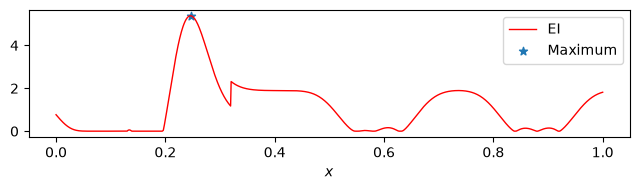

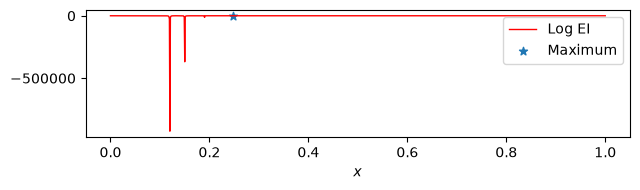

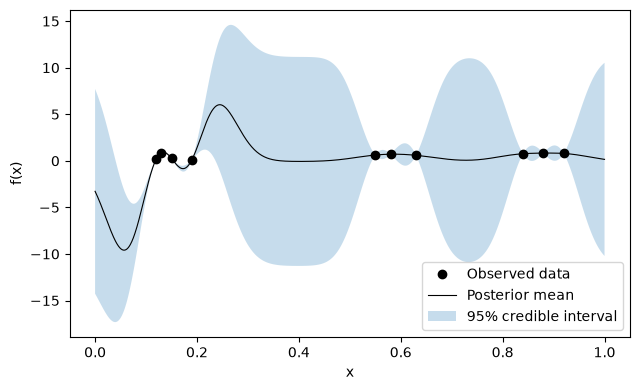

In [8]:

def plot_acq(train_x:Tensor,
            train_y:Tensor,
            best_y:float, 
            acq_fun:Callable=EI,
            mean_function:Mean=mean_function_,
            kernel:Kernel=kernel_,
            likelihood:FixedNoiseGaussianLikelihood=likelihood_,
            acq_fun_name:str = "EI",
            plot_max:bool = True,
            n_samples:int = 100):
    
    # Preserve train_x's device and use double precision.
    train_x = train_x.to(dtype=torch.double)
    train_y = train_y.to(dtype=torch.double, device=train_x.device)

    if train_x.ndim == 1:
        train_x = train_x.unsqueeze(-1)

    if train_y.ndim == 1:
        train_y = train_y.unsqueeze(-1)

    ##### TODO:  Enter your code here:

    # fit
    # Initialize the GPR model
    GPR = SingleTaskGP(train_x, 
                       train_y,
                       covar_module=kernel,
                       mean_module=mean_function,
                       likelihood=likelihood,
                       outcome_transform=Standardize(m=1))

    # Optimize the hyperparameters of the GPR
    mll = ExactMarginalLogLikelihood(GPR.likelihood, GPR)
    fit_gpytorch_mll(mll)

    # Set the GPR model to evaluation mode
    GPR.eval()

    acq_cum = [] # This list is to store the evaluated aquisition_function
    
    # This array is meant to sample equidistant points and evaluate the acquistion function
    # At those points
    x = torch.linspace(
        0.0, 1.0, n_samples, dtype=train_x.dtype, device=train_x.device
    ).unsqueeze(-1)

    with torch.no_grad():
        for test_x in x:
            pred_mean, pred_std = GPR.posterior(test_x).mean, GPR.posterior(test_x).variance
            acq = acq_fun(pred_mean.cpu().numpy(), pred_std.cpu().numpy(), best_y.ravel())
            
            acq_cum.append(acq.ravel())
    
    ##### --------------- END OF CODE INPUT -----------------------
    fig, ax = plt.subplots(figsize=(6.5, 2))
    x_plot = x.cpu().numpy().ravel()

    ax.plot(x_plot,acq_cum,'r',linewidth=1)


    if plot_max:
        xmax = x_plot[np.argmax(acq_cum)]
        ymax = max(acq_cum)
        ax.scatter(xmax, ymax, marker="*")
        ax.legend([acq_fun_name, "Maximum"])
    else:
        ax.legend([acq_fun_name])

    ax.set_xlabel("$x$")
    fig.tight_layout()

best_y = max(train_y.detach().cpu().numpy().ravel())
print(train_y.cpu().numpy())
print(best_y)


plot_acq(train_x, train_y,best_y=best_y, n_samples=1000)
plot_acq(train_x, train_y,best_y=best_y, acq_fun=log_ei, acq_fun_name="Log EI", n_samples=1000)
plot_prediction(train_x, train_y)


In the previous plots, the maximum of both the Expected Improvement and the Logarithmic Expected Improvement shall coincide in the same point!

Also we can plot different settings for the `UCB`, `LCB` and `POI`.

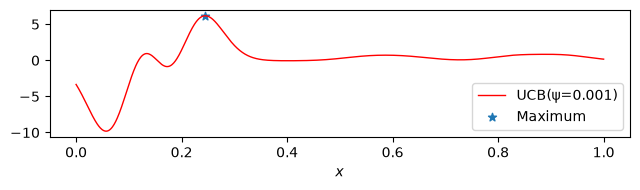

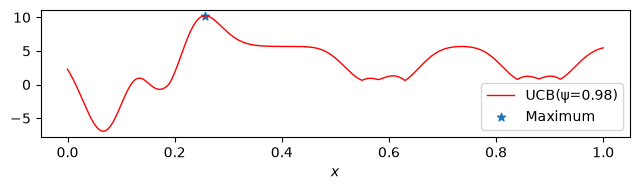

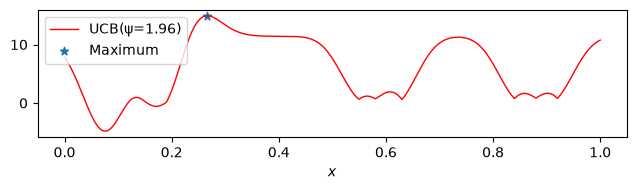

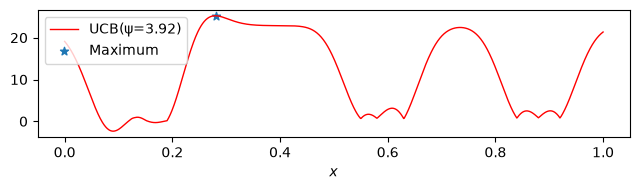

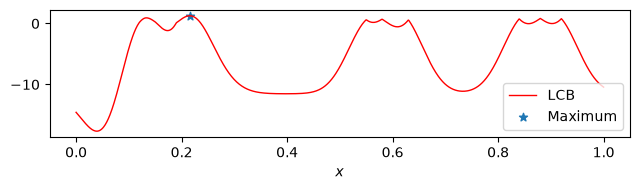

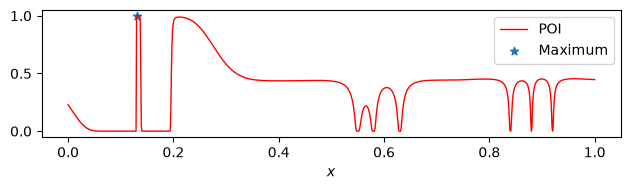

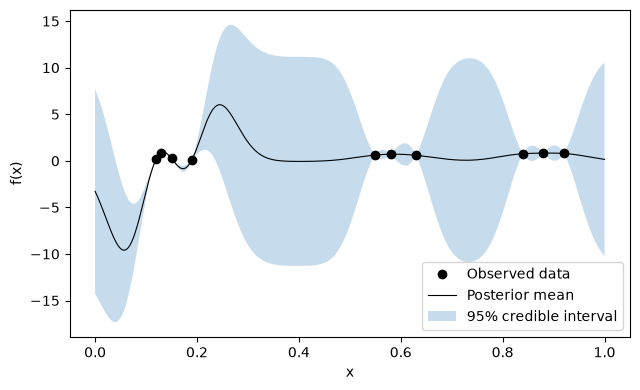

In [9]:
# Other plots

# With varying values of the UCB parameter psi, we can see how the acquisition function changes. 
# The higher the value of psi, the more exploration is encouraged. Check Srinivas et al. (2010) for more details on this.
plot_acq(train_x, train_y,best_y=best_y,acq_fun=partial(ucb, psi=1e-3),acq_fun_name=f"UCB(ψ=0.001)", n_samples=1000)
plot_acq(train_x, train_y,best_y=best_y,acq_fun=partial(ucb, psi=0.98),acq_fun_name=f"UCB(ψ=0.98)", n_samples=1000)
plot_acq(train_x, train_y,best_y=best_y,acq_fun=partial(ucb, psi=1.96),acq_fun_name=f"UCB(ψ=1.96)", n_samples=1000)
plot_acq(train_x, train_y,best_y=best_y,acq_fun=partial(ucb, psi=3.92),acq_fun_name=f"UCB(ψ=3.92)", n_samples=1000)

# The LCB is affected in a similar fashion
plot_acq(train_x, train_y,best_y=best_y,acq_fun=lcb,acq_fun_name="LCB", n_samples=1000)

# The Probability of Improvement (POI) is another acquisition function that can be used.
# You may see it is overly-exploitative
plot_acq(train_x, train_y,best_y=best_y,acq_fun=poi,acq_fun_name="POI", n_samples=1000)
plot_prediction(train_x, train_y)

# Exercise 3

Now you've implemented Expected Improvement (EI) we will implement the weighted EI (WEI) by adding an alpha parameter making it a convex unitary transformation as follows:

$$\mathrm{EI}_n(x;\alpha) = \alpha \sigma_n(x) \varphi\left(\frac{\Delta_n(x)}{\sigma_n(x)}\right) + (1-\alpha)\Delta_n \Phi\left(\frac{\Delta_n(x)}{\sigma_n(x)}\right)$$


In [10]:
from scipy.stats import norm


def WEI(m:float,v:float,best_y:float, alpha:float, minimization:bool = False)-> float:
    
    '''
    This is a base Expected Improvement function. The inputs of this function are:
    - m: The posterior mean
    - v: The posterior variance
    - best_y: The sampled best value of the objective
    - minimization: A boolean handle to determine if the objective is minimized or maximized
    '''

    assert alpha >= 0.00 and alpha <= 1.00, "Alpha must be between 0 and 1"

    ###### TODO: Enter your code here:
    if minimization:
        delta = best_y - m
    else:
        delta =  m - best_y
        
    s = np.sqrt(v)
    z = delta / s if s > 1e-08 else delta
    ret = max(0,delta)
    ret += alpha * s * norm.pdf(z, loc=0) 
    ret -= (1-alpha) * abs(delta)*norm.cdf(-1*abs(z))

    return ret
    
    ##### --------------- END OF CODE INPUT -----------------------



# Test your code!!!
alphas = [0, 0.25, 0.5, 0.75, 1.0]
for alpha in alphas:
    print(WEI(m=1,v=1e-100,best_y=0, alpha=alpha))
    print(WEI(m=2,v=1,best_y=0,alpha=alpha))
    print(WEI(m=0,v=2,best_y=2,alpha=alpha))
    print(WEI(m=0,v=10,best_y=2,alpha=alpha))


0.8413447460685429
1.9544997361036416
-0.15729920705028516
-0.5270892568655381
0.8810085595514072
1.9793725437060283
-0.0660859681101395
-0.1370961689155144
0.9206723730342714
2.004245351308415
0.02512727083000614
0.2528969190345093
0.9603361865171357
2.0291181589108014
0.1163405097701518
0.6428900069845329
1.0
2.053990966513188
0.20755374871029744
1.0328830949345567


In the following block, you may see that by increasing the parameter there will be a transition between pure exploitative behaviour to pure explorative behaviour.

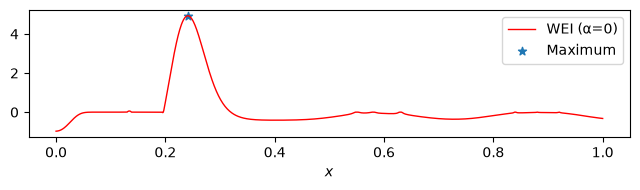

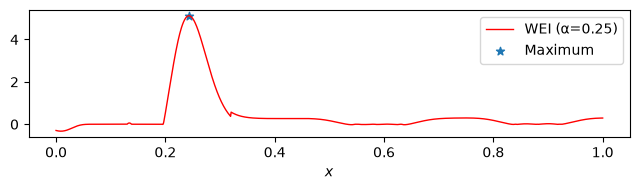

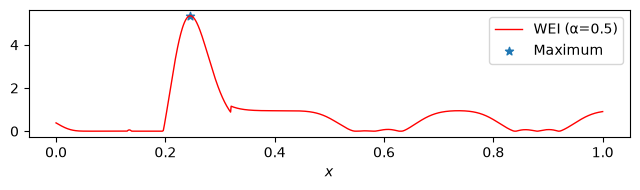

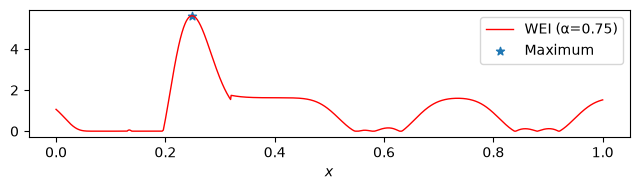

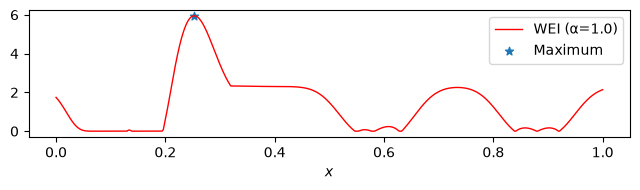

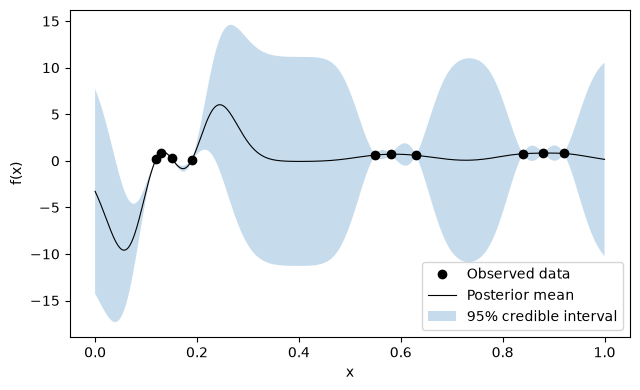

In [11]:
best_y = max(train_y.detach().cpu().numpy().ravel())

for alpha in alphas:
    new_wei = partial(WEI,alpha=alpha)
    plot_acq(train_x, train_y,best_y=best_y,acq_fun=new_wei,acq_fun_name=f"WEI (α={alpha})", n_samples=1000)
plot_prediction(train_x, train_y)

In [12]:
# Imports IOH get problem 
from ioh import get_problem
from ioh.iohcpp.problem import RealSingleObjective

# Imports the IOH Logging environments
from ioh.iohcpp.logger import Analyzer
from ioh.iohcpp.logger.trigger import Trigger, ALWAYS

# Typing Libraries
from typing import Iterable,Union,List,Tuple,Callable, Optional

# Import numpy, warnings and torch libraries 
import numpy as np
import warnings
import torch 
from torch import Tensor, device, float64 #This is relevant for the device to be used (CPU or GPU) and the type of tensor

# Import the BoTorch Libraries
from torch.quasirandom import SobolEngine # To use in this case for the DoE step
from botorch.models.transforms.input import Normalize # This is to normalize the inputs (from 0 to 1 in each dimension)
from botorch.models.transforms.outcome import Standardize # This is to standardize the outputs (0 mean and unit variance)
from botorch.optim import optimize_acqf # This is to optimize the acquisition function
from botorch.acquisition import AcquisitionFunction # This is the base class for the acquisition functions
from botorch.acquisition.analytic import AnalyticAcquisitionFunction # This is the base class for the analytic acquisition functions

# This is to import the Expected Improvement and other acquisition functions
from botorch.acquisition.analytic import ExpectedImprovement, LogExpectedImprovement, UpperConfidenceBound, ProbabilityOfImprovement, LogProbabilityOfImprovement

# this is to import the automatic fitting method to use and 'train' the GP hyperparameters via Maximum Likelihood Estimation
from botorch.fit import fit_gpytorch_mll

# This is to call the decorator to handle the input transformations for the case of batch evaluations in Acquisition Functions
from botorch.utils.transforms import t_batch_mode_transform

from botorch.exceptions import BadInitialCandidatesWarning, ModelFittingError

# This is to import the GPyTorch libraries
from torch.distributions.normal import Normal # This is to handle the normal distribution (for the acquisition functions)



## Exercise #4: Completing the `__call__` Function of the Bayesian Optimizer

### Objective

In this exercise, you will complete the missing implementation of the `__call__` method inside the `BayesianOptimizer` class.

This function performs the **core Bayesian optimization loop** — iteratively training a Gaussian Process (GP) model, selecting new points through an acquisition function, and updating the model until the evaluation budget is reached.

---

### Background

The `__call__` method is responsible for:

1. Generating the **initial design of experiments (DoE)**.
2. Fitting an initial **Gaussian Process (GP)** model.
3. Running an iterative **Bayesian optimization loop**.
4. Returning the **best solution found**.

A portion of the code is already provided — your task is to fill in the missing optimization loop.

---

## Steps to Complete the Task

#### **Step 1 — Review the Setup**

Before the missing section, the method:
- Uses a **Sobol sampler** to create initial samples within the problem bounds.
- Evaluates the objective function at those samples.
- Fits a GP model using:
  ```python
  _, gp_model = self.fit_model(train_X=self.X, train_obj=self.fX)


In the following block you'll see an example of defining a Bayesian Optimization Algorithm class. The following implementation is relevant, since for comparing different optimizers (for benchmarking as we did during Session 1) we require uniform methods, such that for defining and running the algorithms is done in the same way. Notice we use the `__init__` to initialize a object, where we set the acquistion function, the mean and the kernel. Below we set the regular ones as we did for the `BoTorch` tutorial. Yet, if you want to change these objects you might want to do that to check changes on the performance as these items might be considered hyperparameters.

Moreover we added a _fallback_ method whenever the usual `fit_gpytorch_mll` fails. Then it implements the manual training loop that we presented during the `BoTorch` GP fitting notebook.

In [23]:
# This is a class defining a Bayesian Optimizer
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=BadInitialCandidatesWarning)

class BayesianOptimizer:
    r"""
    This class defines an object to perform Optimization in a complete Bayesian Loop from the 
    exact definition.
    """

    def __init__(self, 
                 acquisition_function:AnalyticAcquisitionFunction = LogExpectedImprovement, # The log of the Expected Improvement 
                                                                                            # is used to avoid numerical issues
                 mean:Callable = ConstantMean(),
                 kernel:Callable = ScaleKernel(MaternKernel(nu=2.5, 
                                                            lengthscale_constraint=GreaterThan(1e-3), # This constraints the lengthscale
                                                            raw_lengthscale_constraint=Positive()
                                                            ),
                                                outputscale_constraint=Interval(1e-3, 1e3)
                                              )
                )->None:
        r"""
        This is an the initialization of the class. 

        Args
        ------------
        acquisition_function:AnalyticAcquisitionFunction
            This is the acquisition function to be used in the optimization process. It must be an instance of the
            AnalyticAcquisitionFunction class from BoTorch
        mean:Callable
            This is the mean function to be used in the GP model. It must be an instance of the gpytorch.means.Mean class
        kernel:Callable
            This is the kernel function to be used in the GP model. It must be an instance of the gpytorch.kernels.Kernel class
        ------------
        """
        # Store the acquisition function
        self.__original_acquisition_function = acquisition_function

        # Initialize the arrays to store the sampled values
        self.X:Tensor = []
        self.fX:Tensor = []

        # use a GPU if available
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.dtype = torch.double
        

        # Store the Analytic acquisition function definition as an attribute of the class
        assert issubclass(acquisition_function, AnalyticAcquisitionFunction), "The acquisition function must be an instance"\
                                              "of the AnalyticAcquisitionFunction class"
        self.__original_acquisition_function:AnalyticAcquisitionFunction = acquisition_function

        # Store the kernel and mean functions
        assert issubclass(type(kernel),Kernel), "The kernel must be an instance of the gpytorch.kernels.Kernel class"
        self.__kernel:Callable = kernel 

        assert issubclass(type(mean),Mean), "The mean must be an instance of the gpytorch.means.Mean class"
        self.__mean:Callable = mean

    
    def run(self,problem_instance:RealSingleObjective, 
                 budget:int = 100, 
                 initial_doe_samples:int = 10,
                 random_seed:int = 43)->None:
        r'''
        This method will perform the optimization process. It will use the acquisition function, kernel and mean
        functions defined in the initialization of the class.
        '''

        self.__call__(problem_instance=problem_instance,
                        budget=budget,
                        initial_doe_samples=initial_doe_samples,
                        random_seed=random_seed)
        


    
    def __call__(self, 
                 problem_instance:RealSingleObjective, 
                 budget:int = 100, 
                 initial_doe_samples:int = 10,
                 random_seed:int = 43)->None:
        
        r'''
        This method will perform the optimization process. It will use the acquisition function, kernel and mean
        functions defined in the initialization of the class.

        Args
        ------------
        problem_instance:RealSingleObjective
            This is an instance of the ioh.iohcpp.problem.RealSingleObjective class. It contains the definition of the objective and possible constraint functions
            to be optimized
        budget:int
            This is the total budget of function evaluations to be used in the optimization process
        initial_doe_samples:int
            This is the number of initial samples to be used in the optimization process
        random_seed:int
            This is the random seed to be used in the optimization process
        
        '''

        #### TODO: Implement the optimization loop for the Bayesian Optimizer. The steps are:
        # 1. Get the initial DoE samples using a Sobol sequence
        # 2. Transform the initial DoE samples to the problem bounds
        # 3. Evaluate the objective function at the initial DoE samples
        # 4. Fit the initial model
        # 5. Perform a loop until the budget is exhausted:
        # 5.1. Extract new candidates using the acquisition function
        # 5.2. Evaluate the objective function at the new candidates
        # 5.3 Update the sampled values
        # 5.4. Refit the model

        # Attach the problem instance
        self.problem = problem_instance

        self.budget = budget

        initial_doe = self.initial_doe_samples(n_samples=initial_doe_samples,
                                               n_variables=self.problem.meta_data.n_variables,
                                               random_seed=random_seed)
        
        self.X = initial_doe.to(device=self.device, dtype=self.dtype)

        # Evaluate the model at the initial DOE
        fX = torch.tensor([self.problem(x_i.detach().cpu().numpy()) for x_i in self.X])

        self.fX = fX.to(device=self.device, dtype=self.dtype).unsqueeze(-1)
        
        # Fit initial model
        _, gp_model = self.fit_model(train_X=self.X,
                                train_obj=self.fX) 
        
        
        # Perform a loop until the possible runs are over!
        #Implement for students
        for _ in range(budget - initial_doe_samples):
            
            # Extract new candidates
            new_x_i = self.optimize_acqf_and_get_observation(gp_model=gp_model)
            
            # Compute again the function
            x_i, f_i_evals= self.evaluate_function(new_x_i)

            # Update the sampled values
            self.X = torch.cat((self.X,x_i),dim=0)
            self.fX = torch.cat((self.fX,f_i_evals),dim=0)

            # Refit the model again!
            _, gp_model = self.fit_model(train_X=self.X,
                                train_obj=self.fX)

        # END OF TODO
        
        # Return the best found solution
        best_idx = torch.argmin(self.fX)

        print("The best solution found is: ")
        print("Best idx = ", best_idx.cpu().numpy()+1)
        print("x = ", self.X[best_idx,:].cpu().numpy())
        print("f(x) = ", self.fX[best_idx].cpu().numpy())


    def initial_doe_samples(self, n_samples:int, n_variables:int, random_seed:int = 43)->Tensor:
        r'''
        This method will generate the initial DoE samples using a Sobol sequence. 
        Also the samples will be transformed to the problem bounds. The output will be a tensor of size (n_samples, n_variables) containing the initial DoE samples.


        Args
        ------------
        n_samples:int
            This is the number of initial samples to be generated
        n_variables:int
            This is the number of variables of the problem
        random_seed:int
            This is the random seed to be used in the optimization process

        Returns
        ------------
        initial_doe:Tensor
            This is a tensor of size (n_samples, n_variables) containing the initial DoE samples within the problem bounds.
        '''
        # Get the initial doe
        sampler = SobolEngine(dimension=n_variables,
                                seed=random_seed, scramble=True)
        
        initial_doe:Tensor = sampler.draw(n_samples, dtype=self.dtype).to(device=self.device)

        # Transform the initial doe to the problem bounds
        #Implementation for students
        for ii in range(n_variables):
            initial_doe[:,ii] = self.bounds[0,ii] + (self.bounds[1,ii] - self.bounds[0,ii]) * initial_doe[:,ii]

        initial_doe = initial_doe.reshape((n_samples,
                                           n_variables))

        return initial_doe
          
           
    def fit_model(self,
                  train_X:Tensor, 
                  train_obj:Tensor,
                  optimizer_steps:int=100)->Tuple[ExactMarginalLogLikelihood,SingleTaskGP]:
        
        """
        This overload will use the same definition as before. The output is a ExactMarginalLogLikelihood object and
        a SingleTaskGP Object. In the case of the SingleTaskGP object, it will correspond to the GP of the objective function
        
        Args
        ------------
        train_X:Tensor
            This is a tensor of size (n_samples, n_features) containing the sampled input locations
        train_obj:Tensor
            This is a tensor of size (n_samples, 1) containing the sampled objective function
        optimizer_steps:int
            This is the number of steps to be used in the optimization of the hyperparameters of the GP model. The default value is 100
        ------------

        Returns
        ------------
        mll:ExactMarginalLogLikelihood
            This is the Exact Marginal Log Likelihood object corresponding to the objective function GP model
        model_obj:SingleTaskGP
            This is the Single Task GP model corresponding to the objective function
        """


        # Define a fixed noise likelihood with very small noise to emulate a noisefree model
        noisefree_variance = 0.0001
        noises = torch.ones(len(train_obj)) * noisefree_variance
        noise_free_likelihood = FixedNoiseGaussianLikelihood(noise=noises)

        
        # Define models for objective and constraint
        model_obj = SingleTaskGP(
            train_X=train_X,
            train_Y=train_obj,
            ### NOTE: These modules are used to normalize the inputs and standardize the outputs for better numerical stability
            input_transform=Normalize(d=train_X.shape[-1],
                                      bounds=self.bounds),
            outcome_transform=Standardize(m=train_obj.shape[-1]),
            ### END OF NOTE
            likelihood= noise_free_likelihood,
            mean_module=self.mean,
            covar_module=self.kernel

        ).to(device=self.device)

        # Wrap the model into a Marginal Log Likelihood Computation
        mll = ExactMarginalLogLikelihood(likelihood=model_obj.likelihood,
                                         model=model_obj)

        # Train the model(s) like in the tutorial
        try:
            fit_gpytorch_mll(mll)
        except ModelFittingError as e:
            # USe a fallback and use manual optimization of the hyperparameters
            warnings.warn("Model fitting failed. Using fallback optimization.", ModelFittingError)
            # Set the model to training mode
            model_obj.train()
            # Use the Adam optimizer to optimize the hyperparameters
            optimizer = torch.optim.Adam(model_obj.parameters(), lr=0.1)

            # Use the marginal log likelihood as the loss function
            mll = ExactMarginalLogLikelihood(model_obj.likelihood, model_obj)
            # Perform a few steps of optimization
            for _ in range(optimizer_steps):
                optimizer.zero_grad()
                output = model_obj(train_X)
                loss = -mll(output, train_obj)
                loss.backward()
                optimizer.step()

        finally:
            model_obj.eval()

        return mll, model_obj
    
    def reset(self)->None:
        r'''
        This method will reset the sampled values and the problem instance
        '''
        self.X = []
        self.fX = []
        self.__problem = None
        self.__bounds = None

      
    
    def optimize_acqf_and_get_observation(self,gp_model:SingleTaskGP)->Tensor:
        
        """
        This function is responsible of using the fitted GP Model and get the new possible values .

        Args
        ------------
        gp_model:SingleTaskGP
            This is the fitted Single Task GP model corresponding to the objective function
        ------------
        """
        # Get the best function evaluation
        best_f = self.fX.min().item()
        objective_acq = self.acq_fun(model=gp_model, 
                                    best_f=best_f,
                                    maximize=False)


        
        # NOTE: This is set since we are only looking for one candidate at each iteration since 
        #       we're using Analytic Acquisition Functions. For batch acquisition functions, this should be
        #       changed to the corresponding batch size set by the user when initializing the Acquisition Function

        q_samples:int = 1


        # Pass the Constrained Expected Improvement function to the Default BoTorch Acquisition Function Optimizer
        candidate, acq_value = optimize_acqf(
                                                acq_function=objective_acq,
                                                bounds=self.bounds,
                                                q=q_samples,
                                                num_restarts=20,
                                                raw_samples=512,
                                        )
        
        return candidate.detach().reshape(shape=(q_samples,self.problem.meta_data.n_variables))
    
    def evaluate_function(self,new_x:Tensor)->Tuple[Tensor,Tensor]:
        r"""
        This function evaluates the objective and constraint functions at the new possible candidates
        """
        # Evaluate the objective function
        f_evals = torch.tensor([self.problem(x_i.detach().cpu().numpy()) for x_i in new_x],
                               device=self.device,
                               dtype=self.dtype).unsqueeze(-1)
        
        return new_x, f_evals   

    @property
    def acq_fun(self)->AnalyticAcquisitionFunction:
        r'''
        This is a property to get the acquisition function
        '''
        return self.__original_acquisition_function
    
    @acq_fun.setter
    def acq_fun(self, acquisition_function:AnalyticAcquisitionFunction)->None:
        assert issubclass(acquisition_function, AnalyticAcquisitionFunction, "The acquisition function must be"\
                                                                              " an instance of the AnalyticAcquisitionFunction class"
                        )   
        self.__original_acquisition_function = acquisition_function
    
    @property
    def kernel(self)->Callable:
        return self.__kernel
    
    @kernel.setter
    def kernel(self, kernel:Callable)->None:
        assert issubclass(type(kernel),Kernel), "The kernel must be an instance of the gpytorch.kernels.Kernel class"
        self.__kernel = kernel
    
    @property
    def mean(self)->Callable:
        return self.__mean
    
    @mean.setter
    def mean(self, mean:Callable)->None:
        assert issubclass(type(mean),Mean), "The mean must be an instance of the gpytorch.means.Mean class"
        self.__mean = mean
    
    @property
    def problem(self)->RealSingleObjective:
        r'''
        This is a property to get the problem instance
        '''
        return self.__problem
    
    @problem.setter
    def problem(self, problem_instance:RealSingleObjective)->None:
        '''

        Args
        ------------
        problem_instance:Problem
            This is an instance of the cocoex.Problem class. It contains the definition of the
            objective and constraint functions to be optimized
        ------------
        '''
        assert isinstance(problem_instance, RealSingleObjective), "The problem instance must be an instance of the"\
                                                                  "ioh.iohcpp.problem.RealSingleObjective class"
        self.__problem = problem_instance

        # Store the bounds of the problem
        self.__bounds = torch.tensor([problem_instance.bounds.lb.ravel(),
                                    problem_instance.bounds.ub.ravel()],
                                   device=self.device,
                                   dtype=self.dtype)

    @property
    def best_index(self)->int:
        r'''
        This is a property to get the index of the best solution found
        '''
        return torch.argmin(self.fX).item()
    
    @property
    def bounds(self)->Tensor:
        return self.__bounds

    @property
    def current_index(self)->int:
        r'''
        This is a property to get the current index of the best solution found
        '''
        return self.fX.shape[0]

    @property
    def budget(self)->int:
        r'''
        This is a property to get the budget of the optimization process
        '''
        return self.__budget

    @budget.setter
    def budget(self, budget:int)->None:
        assert isinstance(budget, int), "The budget must be an integer"
        self.__budget = budget
        

Run the following block to check your implementation!

In [19]:
# Set the dimension of the problem
DIMENSION = 2
FID = 16

# Test the Bayesian Optimizer class
bo = BayesianOptimizer(kernel=ScaleKernel(MaternKernel(nu=1.5,
                                                lengthscale_constraint=Interval(1e-3, 1e3), # This constraints the lengthscale
                                                ard_num_dims=DIMENSION
                                                
                                                ),
                                    raw_outputscale_constraint=Interval(1e-3, 1e3)
                                    ),
                        mean=ConstantMean(),
                        acquisition_function=LogExpectedImprovement)


# Call a problem from the IOH library.
problem = get_problem(fid=FID, instance=0, dimension=DIMENSION)

# Print the problem information (name, instance, dimension)
print("Problem Name: ", problem.meta_data.name, 
      ", Problem Instance: ", problem.meta_data.instance, 
      ", Problem Dimension: ", problem.meta_data.n_variables)

# Print the optimum of the problem
print("x*: ", problem.optimum.x, "f(x*): ", problem.optimum.y)

# Run the Bayesian Optimizer
bo.run(problem_instance=problem,
       random_seed=48, initial_doe_samples=2*DIMENSION, budget=30*DIMENSION)

# Distance and regret
print("Distance to optimum: ", np.linalg.norm(bo.X[bo.best_index].detach().cpu().numpy() - problem.optimum.x,2))
print("Regret: ", abs(np.min(bo.fX.detach().cpu().numpy()) - problem.optimum.y))

# Reset the state of the Bayesian Optimizer and problem
bo.reset()

Problem Name:  Weierstrass , Problem Instance:  0 , Problem Dimension:  2
x*:  [-1.6368  0.5208] f(x*):  -260.22
The best solution found is: 
Best idx =  58
x =  [-4.20693508 -5.        ]
f(x) =  [-258.9212195]
Distance to optimum:  6.08973127058942
Regret:  1.298780502923762


## Playground Problems
1) Change parameters of the kernel and mean function from the exercises. Check how this affects the posterior prediction and also how does it compounds to the evaluation of the acquisition function
2) Modify the `BayesianOptimizer` class such that an scheduler is implemented and use `UpperConfidenceBound` as an Acquisition Function. An scheduler is either an agent or a function (example a cosine) which changes the behaviour of the overall algorithm from purely explorative to more exploitative. Check what happens for certain functions if such idea works better.

In [33]:
class BayesianOptimizerWScheduler(BayesianOptimizer):
    r"""
    This class defines an object to perform Optimization in a complete Bayesian Loop from the 
    exact definition. It extends the BayesianOptimizer class to include a scheduler for the acquisition function.
    """

    def __init__(self, 
                 mean:Callable = ConstantMean(),
                 kernel:Callable = ScaleKernel(MaternKernel(nu=2.5, 
                                                            lengthscale_constraint=GreaterThan(1e-3), # This constraints the lengthscale
                                                            raw_lengthscale_constraint=Positive()
                                                            ),
                                                outputscale_constraint=Interval(1e-3, 1e3)
                                              ),
                 scheduler:Optional[Callable] = None
                )->None:
        r"""
        This is an the initialization of the class. 

        Args
        -----------
        mean:Callable
            This is the mean function to be used in the GP model. It must be an instance of the gpytorch.means.Mean class
        kernel:Callable
            This is the kernel function to be used in the GP model. It must be an instance of the gpytorch.kernels.Kernel class
        scheduler:Optional[Callable]
            This is an optional scheduler for the acquisition function. It should be a callable that takes in the current iteration and returns a modified acquisition function.
        ------------
        """
        acquisition_func = UpperConfidenceBound
        super().__init__(acquisition_function=acquisition_func, mean=mean, kernel=kernel)

        if scheduler is not None:
            assert callable(scheduler), "The scheduler must be a callable"
            self.scheduler = scheduler
        else:
            # Assign a cosine function scheduler as default
            self.scheduler = lambda iter_budget_pair : 3.98 * np.cos(np.pi/2 * iter_budget_pair[0] / iter_budget_pair[1])  + 0.01

    def optimize_acqf_and_get_observation(self, gp_model:SingleTaskGP)->Tensor:
        r"""
        This function is responsible for using the fitted GP Model and getting the new possible values, with an optional scheduler for the acquisition function.
        Given that we are using the Upper Confidence Bound (UCB) acquisition function, we can modify the exploration parameter based on the iteration number.

        Args
        ------------
        gp_model:SingleTaskGP
            This is the fitted Single Task GP model corresponding to the objective function.
        """

        
        # Get the best function evaluation
        best_f = self.fX.min().item()

        # Get the beta parameter from the scheduler based on the current iteration and budget
        beta = self.scheduler((self.current_index, self.budget))



        objective_acq = self.acq_fun(model=gp_model, 
                                    beta=beta,
                                    maximize=False)


        
        # NOTE: This is set since we are only looking for one candidate at each iteration since 
        #       we're using Analytic Acquisition Functions. For batch acquisition functions, this should be
        #       changed to the corresponding batch size set by the user when initializing the Acquisition Function

        q_samples:int = 1


        # Pass the Constrained Expected Improvement function to the Default BoTorch Acquisition Function Optimizer
        candidate, acq_value = optimize_acqf(
                                                acq_function=objective_acq,
                                                bounds=self.bounds,
                                                q=q_samples,
                                                num_restarts=20,
                                                raw_samples=512,
                                        )
        
        return candidate.detach().reshape(shape=(q_samples,self.problem.meta_data.n_variables))
    

In [35]:
# Set the dimension of the problem
DIMENSION = 2
FID = 16

# Test the Bayesian Optimizer class
bo_ws = BayesianOptimizerWScheduler(kernel=ScaleKernel(MaternKernel(nu=1.5,
                                                lengthscale_constraint=Interval(1e-3, 1e3), # This constraints the lengthscale
                                                ard_num_dims=DIMENSION
                                                
                                                ),
                                    raw_outputscale_constraint=Interval(1e-3, 1e3)
                                    ),
                        mean=ConstantMean(),
                       )


# Call a problem from the IOH library.
problem = get_problem(fid=FID, instance=0, dimension=DIMENSION)

# Print the problem information (name, instance, dimension)
print("Problem Name: ", problem.meta_data.name, 
      ", Problem Instance: ", problem.meta_data.instance, 
      ", Problem Dimension: ", problem.meta_data.n_variables)

# Print the optimum of the problem
print("x*: ", problem.optimum.x, "f(x*): ", problem.optimum.y)

# Run the Bayesian Optimizer
bo_ws.run(problem_instance=problem,
       random_seed=48, initial_doe_samples=2*DIMENSION, budget=30*DIMENSION)

# Distance and regret
print("Distance to optimum: ", np.linalg.norm(bo_ws.X[bo_ws.best_index].detach().cpu().numpy() - problem.optimum.x,2))
print("Regret: ", abs(np.min(bo_ws.fX.detach().cpu().numpy()) - problem.optimum.y))

# Reset the state of the Bayesian Optimizer and problem
bo_ws.reset()

Problem Name:  Weierstrass , Problem Instance:  0 , Problem Dimension:  2
x*:  [-1.6368  0.5208] f(x*):  -260.22
The best solution found is: 
Best idx =  53
x =  [-2.06157113 -3.51419099]
f(x) =  [-258.10254374]
Distance to optimum:  4.057287620275558
Regret:  2.117456261928737
